# A2 — Data Alignment | Simon Solar
**PV Performance Modeling in Practice — CBENS 2026**

**Objetivo:** investigar a defasagem de aproximadamente **4 horas** entre potência modelada e medida **antes de deslocar ou corrigir qualquer série**. Vamos carregar os dados novamente, inspecionar as convenções de horário e usar a irradiância POA como teste independente do modelo elétrico.

**Arquivos:**
- `field_data/9069_subset_hourly.csv` — dados PVDAQ pré-agregados, timestamp HH:30 (os horários ainda estão **sob investigação**).
- `weather_data/Simon_Solar_NSRDB_2016_2023.csv` — NSRDB, timestamp HH:30, horário padrão UTC−5.
- `field_data/9069_subset.csv` — **opcional**, PVDAQ bruto: permite reconstituir a transformação feita na origem e inspecionar o procedimento do Brian.

> **Importante:** um pico de correlação após deslocar uma série **não determina qual fonte está correta**. Os deslocamentos abaixo são apenas diagnósticos: nenhum arquivo original será modificado.


## A. Recarregar e inspecionar os arquivos
A análise mantém todos os instantes num **fuso de exibição comum: UTC−5 fixo** (`Etc/GMT+5`). `tz_convert` preserva o instante físico; `tz_localize` *atribui* um fuso a um horário sem fuso. Confundir os dois pode deslocar as curvas em horas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pvlib
from IPython.display import display

TZ = "Etc/GMT+5"  # UTC-5 fixo, sem horário de verão
FIELD = Path("field_data/9069_subset_hourly.csv")
WEATHER = Path("weather_data/Simon_Solar_NSRDB_2016_2023.csv")
RAW = Path("field_data/9069_subset.csv")  # opcional

def load_indexed_csv(path):
    df = pd.read_csv(path)
    time_col = next((c for c in ["timestamp", "utc_measured_on", "measured_on"] if c in df), None)
    if time_col is None:
        raise KeyError(f"Coluna de tempo não encontrada em {path}; primeiras colunas: {df.columns[:6].tolist()}")
    timestamps = pd.to_datetime(df.pop(time_col), utc=True, errors="raise")
    df.index = pd.DatetimeIndex(timestamps).tz_convert(TZ)
    df.index.name = "timestamp"
    return df.sort_index().apply(pd.to_numeric, errors="coerce")

field = load_indexed_csv(FIELD)
weather = load_indexed_csv(WEATHER)
for name, df in [("PVDAQ horário", field), ("NSRDB", weather)]:
    print(f"{name}: {len(df):,} linhas; de {df.index.min()} a {df.index.max()}")
    print("  Minutos:", sorted(df.index.minute.unique()), "| duplicados:", df.index.duplicated().sum())
    display(df.head(2))

PVDAQ horário: 68,205 linhas; de 2016-02-17 13:30:00-05:00 a 2023-11-29 09:30:00-05:00
  Minutos: [30] | duplicados: 0


,meter_1_ac_power_kw,meter_2_ac_power_kw,poa_irradiance_02a,poa_irradiance_02b,poa_irradiance_08,ghi_irradiance,reference_cell_poa_median,reference_cell_poa_1,module_temperature_median,ambient_temperature_median,...,inverter_33_ac_power_(kw),inverter_34_ac_power_(kw),inverter_35_ac_power_(kw),inverter_36_ac_power_(kw),inverter_37_ac_power_(kw),inverter_38_ac_power_(kw),inverter_39_ac_power_(kw),inverter_40_ac_power_(kw),meter_1_ac_power_kw_n_samples,meter_2_ac_power_kw_n_samples
timestamp,,,,,,,,,,,,,,,,,,,,,
2016-02-17 13:30:00-05:00,42.727273,NaN,16.878182,8.277273,6.236,NaN,5.470,-0.878182,7.837273,10.43,...,1.527273,1.654545,1.736364,1.554545,1.872727,1.690909,1.727273,1.563636,NaN,NaN
2016-02-17 14:30:00-05:00,-60.000000,NaN,13.508333,6.565833,1.270,NaN,0.375,-5.672727,5.912500,8.68,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN


NSRDB: 70,080 linhas; de 2016-01-01 00:30:00-05:00 a 2023-12-31 23:30:00-05:00
  Minutos: [30] | duplicados: 0


,Year,Month,Day,Hour,Minute,temp_air,Alpha,Aerosol Optical Depth,Asymmetry,dhi_clear,...,relative_humidity,solar_zenith,SSA,albedo,pressure,precipitable_water,wind_direction,wind_speed,Global Horizontal UV Irradiance (280-400nm),Global Horizontal UV Irradiance (295-385nm)
timestamp,,,,,,,,,,,,,,,,,,,,,
2016-01-01 00:30:00-05:00,2016,1,1,0,30,8.8,1.32,0.049,0.62,0.0,...,94.19,169.21,0.95,0.12,992.0,1.8,305.0,0.5,0.0,0.0
2016-01-01 01:30:00-05:00,2016,1,1,1,30,8.3,1.31,0.048,0.62,0.0,...,95.05,164.37,0.95,0.12,992.0,1.8,305.0,0.5,0.0,0.0


### A1. Conferir o que `tz_convert` e `tz_localize` fazem
O nome `utc_measured_on` não prova que o instante está em UTC. Vamos primeiro olhar **a string original**, sem converter nada.

In [2]:
for label, file in [("PVDAQ horário", FIELD), ("NSRDB", WEATHER)]:
    sample = pd.read_csv(file, nrows=4)
    col = next(c for c in ["timestamp", "utc_measured_on", "measured_on"] if c in sample)
    print(f"\n{label}: coluna '{col}' como aparece no CSV")
    display(sample[[col]])
    print("Interpretado em UTC−5:")
    display(pd.to_datetime(sample[col], utc=True).dt.tz_convert(TZ))


PVDAQ horário: coluna 'timestamp' como aparece no CSV


,timestamp
0,2016-02-17 13:30:00-05:00
1,2016-02-17 14:30:00-05:00
2,2016-02-17 15:30:00-05:00
3,2016-02-17 16:30:00-05:00


Interpretado em UTC−5:


0   2016-02-17 13:30:00-05:00
1   2016-02-17 14:30:00-05:00
2   2016-02-17 15:30:00-05:00
3   2016-02-17 16:30:00-05:00
Name: timestamp, dtype: datetime64[ns, Etc/GMT+5]


NSRDB: coluna 'timestamp' como aparece no CSV


,timestamp
0,2016-01-01 00:30:00-05:00
1,2016-01-01 01:30:00-05:00
2,2016-01-01 02:30:00-05:00
3,2016-01-01 03:30:00-05:00


Interpretado em UTC−5:


0   2016-01-01 00:30:00-05:00
1   2016-01-01 01:30:00-05:00
2   2016-01-01 02:30:00-05:00
3   2016-01-01 03:30:00-05:00
Name: timestamp, dtype: datetime64[ns, Etc/GMT+5]

### A2. Revisitar o PVDAQ bruto (se disponível)
O arquivo original tem muitas colunas. Lemos **apenas as necessárias**. Compare as strings brutas com os timestamps do arquivo horário; assim saberemos se a discrepância já existia **antes** do resampling. O código do Brian descartava o timezone (`tz_localize(None)`), relocalizava em `America/New_York` e adicionava **+5 horas**. Vamos examinar essa hipótese sem adotá-la como verdade.

In [3]:
if RAW.exists():
    raw_head = pd.read_csv(RAW, nrows=5)
    print("Exemplos originais:")
    display(raw_head.iloc[:, :3])
    original_time_col = next((x for x in ["utc_measured_on", "timestamp", "measured_on"] if x in raw_head), raw_head.columns[0])
    raw_strings = raw_head[original_time_col].astype(str)
    parsed = pd.to_datetime(raw_strings, utc=True)
    demonstration = pd.DataFrame({
        "string_original": raw_strings,
        "conversao_UTC-5": parsed.dt.tz_convert(TZ).astype(str),
        "apenas_horario_sem_fuso": raw_strings.str.slice(0, 19)
    })
    display(demonstration)
    print("Inspecione as horas originais e o que acontece ao converter; NÃO aplique ainda correções.")
else:
    print(f"Arquivo bruto não encontrado: {RAW}")
    print("A análise com o arquivo horário continuará. Para auditar a geração deste arquivo, copie o CSV bruto para field_data/.")

Exemplos originais:


,utc_measured_on,meter_1_ac_power_kw,meter_2_ac_power_kw
0,2016-02-17 13:05:00-05:00,560.0,NaN
1,2016-02-17 13:10:00-05:00,320.0,NaN
2,2016-02-17 13:15:00-05:00,70.0,NaN
3,2016-02-17 13:20:00-05:00,-60.0,NaN
4,2016-02-17 13:25:00-05:00,-60.0,NaN


,string_original,conversao_UTC-5,apenas_horario_sem_fuso
0,2016-02-17 13:05:00-05:00,2016-02-17 13:05:00-05:00,2016-02-17 13:05:00
1,2016-02-17 13:10:00-05:00,2016-02-17 13:10:00-05:00,2016-02-17 13:10:00
2,2016-02-17 13:15:00-05:00,2016-02-17 13:15:00-05:00,2016-02-17 13:15:00
3,2016-02-17 13:20:00-05:00,2016-02-17 13:20:00-05:00,2016-02-17 13:20:00
4,2016-02-17 13:25:00-05:00,2016-02-17 13:25:00-05:00,2016-02-17 13:25:00


Inspecione as horas originais e o que acontece ao converter; NÃO aplique ainda correções.


## B. Teste independente: irradiância POA medida × POA calculada
Não usaremos potência elétrica nesta etapa. A posição do Sol, irradiância NSRDB e geometria da usina determinam a POA calculada. Se **a POA já estiver defasada**, o problema vem antes das perdas DC/AC e do inversor.

**Atenção:** `poa_irradiance_02a` pode ter erros próprios, sombreamento ou calibração; a melhor correlação em um intervalo extenso é evidência de **alinhamento relativo**, não uma validação absoluta do relógio.

In [4]:
needed = ["ghi", "dni", "dhi", "temp_air", "wind_speed"]
assert all(k in weather for k in needed), f"Colunas NSRDB ausentes: {[k for k in needed if k not in weather]}"
assert "poa_irradiance_02a" in field, "POA de campo não encontrada. Confira o arquivo de origem."

location = pvlib.location.Location(33.6762, -83.67633, tz=TZ, name="Simon Solar")
solpos = location.get_solarposition(weather.index)
poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=20, surface_azimuth=180,
    solar_zenith=solpos["apparent_zenith"], solar_azimuth=solpos["azimuth"],
    dni=weather["dni"], ghi=weather["ghi"], dhi=weather["dhi"],
    albedo=0.20, model="isotropic"
)
poa_model = poa["poa_global"].rename("POA NSRDB/pvlib (W/m²)")
poa_field = field["poa_irradiance_02a"].rename("POA PVDAQ (W/m²)")
print("POA calculada e medição carregadas.")

POA calculada e medição carregadas.


### B1. Localizar o deslocamento que maximiza a correlação
**Definição:** `shift(+h, freq="h")` desloca os **timestamps da série medida** para mais tarde. O modelo fica intocado. Usamos os mesmos horários coincidentes em cada comparação, excluindo `NaN`.

Compare o resultado no ano inteiro e **também por estação**; não decida só pelo máximo global.

,Correlação,Horas coincidentes
Deslocamento PVDAQ (h),,
4,0.525058,25076
5,0.509749,25076
3,0.481298,25076
6,0.445679,25076
2,0.399421,25076
7,0.348836,25076
1,0.295413,25076
8,0.234563,25076
0,0.182809,25076


Melhor deslocamento relativo da POA de campo: +4 h


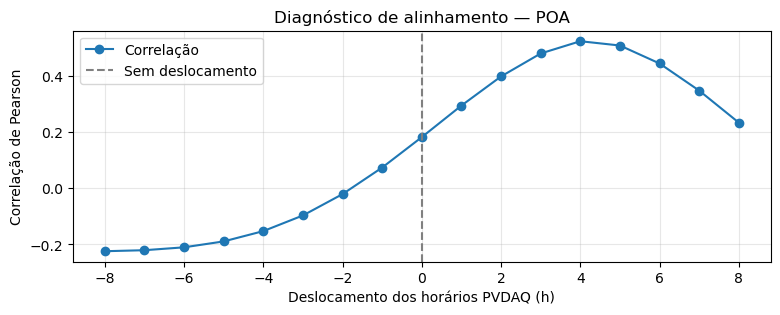

In [5]:
def scan_offsets(measured, reference, hours=range(-8, 9)):
    rows = []
    for h in hours:
        pair = pd.concat([reference, measured.shift(h, freq="h")], axis=1).dropna()
        rows.append({"Deslocamento PVDAQ (h)": h,
                     "Correlação": pair.iloc[:, 0].corr(pair.iloc[:, 1]) if len(pair) > 1 else np.nan,
                     "Horas coincidentes": len(pair)})
    return pd.DataFrame(rows).set_index("Deslocamento PVDAQ (h)")

poa_scan = scan_offsets(poa_field, poa_model)
display(poa_scan.sort_values("Correlação", ascending=False).head(10))
best_poa_shift = int(poa_scan["Correlação"].idxmax())
print(f"Melhor deslocamento relativo da POA de campo: {best_poa_shift:+d} h")
ax = poa_scan["Correlação"].plot(marker="o", figsize=(9, 3), legend=False)
ax.axvline(0, color="gray", linestyle="--", label="Sem deslocamento")
ax.set(xlabel="Deslocamento dos horários PVDAQ (h)", ylabel="Correlação de Pearson",
       title="Diagnóstico de alinhamento — POA"); ax.grid(alpha=.3); ax.legend(); plt.show()

### B2. Visualizar uma semana, com e sem deslocamento
A série `+h` é apenas **uma hipótese**, para comparar formas e os horários de início/fim da geração. O fato de ela se aproximar da POA calculada não garante que os timestamps originais estejam errados.

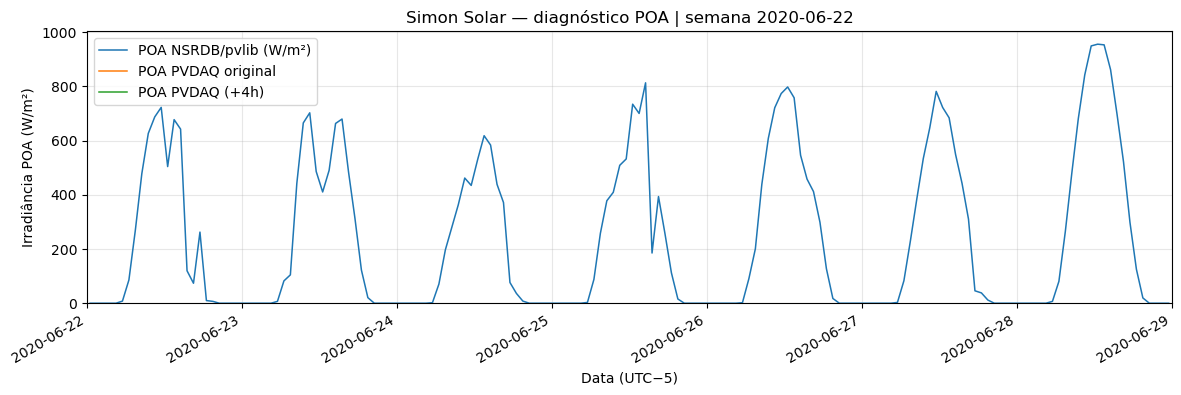

In [6]:
week = "2020-06-22"  # altere para outra semana, inclusive no inverno
start = pd.Timestamp(week).tz_localize(TZ)
end = start + pd.Timedelta(days=7)
compare_poa = pd.concat([
    poa_model,
    poa_field.rename("POA PVDAQ original"),
    poa_field.shift(best_poa_shift, freq="h").rename(f"POA PVDAQ ({best_poa_shift:+d}h)")
], axis=1).loc[(lambda x: (x.index >= start) & (x.index < end))]
ax = compare_poa.plot(figsize=(14, 4), linewidth=1.1)
ax.set(title=f"Simon Solar — diagnóstico POA | semana {week}",
       xlabel="Data (UTC−5)", ylabel="Irradiância POA (W/m²)", xlim=(start, end), ylim=(0, None))
ax.grid(alpha=.3); ax.legend(); plt.show()

## C. O deslocamento muda ao longo do ano?
Se a diferença se aproxima de **uma hora adicional no verão**, investigue horário de verão (`America/New_York`), lembrando que NSRDB está em **UTC−5 fixo**. Se a defasagem for parecida em todas as estações, procure a interpretação do timestamp original/offset. Correlação por estação também pode ser afetada por cobertura de dados, nuvens e amostras insuficientes.

In [7]:
segments = {
    "Verão 2020 (jun–ago)": ("2020-06-01", "2020-08-31"),
    "Inverno 2020/21 (dez–fev)": ("2020-12-01", "2021-02-28"),
    "Verão 2022 (jun–ago)": ("2022-06-01", "2022-08-31"),
    "Inverno 2022/23 (dez–fev)": ("2022-12-01", "2023-02-28"),
}
results = []
for name, (begin, finish) in segments.items():
    # Corte aplicado ao tempo de referência, ANTES de deslocar o dado medido
    lo = pd.Timestamp(begin).tz_localize(TZ)
    hi = pd.Timestamp(finish).tz_localize(TZ) + pd.Timedelta(days=1)
    model_part = poa_model.loc[(poa_model.index >= lo) & (poa_model.index < hi)]
    field_part = poa_field.loc[(poa_field.index >= lo - pd.Timedelta(hours=8)) &
                               (poa_field.index < hi + pd.Timedelta(hours=8))]
    scan = scan_offsets(field_part, model_part)
    if scan["Correlação"].notna().any():
        best = int(scan["Correlação"].idxmax())
        results.append({"Período": name, "Melhor deslocamento (h)": best,
                        "Correlação": scan.loc[best, "Correlação"],
                        "Horas coincidentes": int(scan.loc[best, "Horas coincidentes"])})
display(pd.DataFrame(results))

""


## D. Checagem de coerência com o Sol
A usina fica na Geórgia (longitude −83,676°). Vamos visualizar **elevação solar**, POA calculada e POA medida. Este teste ajuda a decidir **qual relógio merece investigação**, sem presumir que Brian ou nosso pré-processamento estejam certos.

Um erro fixo de quatro horas é **grande demais para ser explicado apenas por horário de verão**. Por outro lado, *qualquer* deslocamento temporal pode mascarar divergências reais entre satélite e sensor.

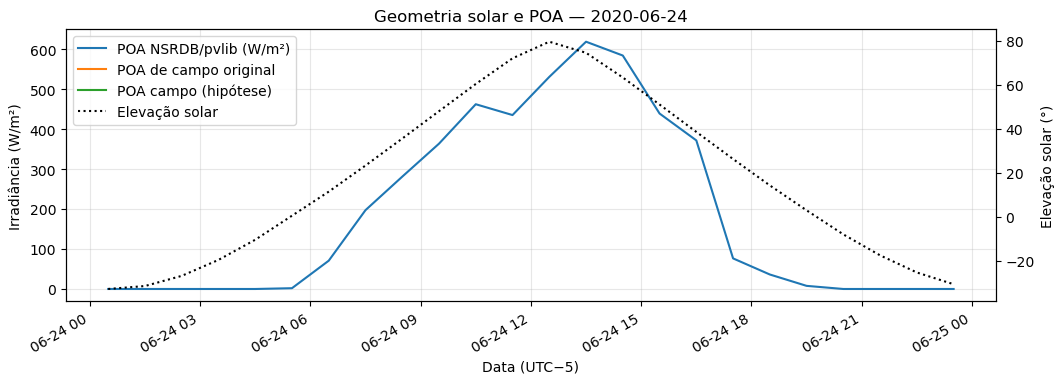

In [8]:
day = "2020-06-24"
start = pd.Timestamp(day).tz_localize(TZ)
end = start + pd.Timedelta(days=1)
view = pd.concat([
    poa_model, poa_field.rename("POA de campo original"),
    poa_field.shift(best_poa_shift, freq="h").rename("POA campo (hipótese)"),
    (90 - solpos["apparent_zenith"]).rename("Elevação solar (°)")
], axis=1)
view = view.loc[(view.index >= start) & (view.index < end)]
fig, ax = plt.subplots(figsize=(12, 4))
for name in [poa_model.name, "POA de campo original", "POA campo (hipótese)"]:
    ax.plot(view.index, view[name], label=name)
ax2 = ax.twinx()
ax2.plot(view.index, view["Elevação solar (°)"], color="black", linestyle=":", label="Elevação solar")
ax.set(ylabel="Irradiância (W/m²)", xlabel="Data (UTC−5)", title=f"Geometria solar e POA — {day}")
ax2.set(ylabel="Elevação solar (°)")
l1, t1 = ax.get_legend_handles_labels(); l2, t2 = ax2.get_legend_handles_labels()
ax.legend(l1 + l2, t1 + t2, loc="upper left"); ax.grid(alpha=.3)
fig.autofmt_xdate(); plt.show()

## E. Auditoria da transformação do PVDAQ bruto (opcional, sem alterar dados)
Se o CSV original estiver disponível, comparamos três **interpretações candidatas** dos seus timestamps: (1) respeitar o offset informado; (2) ignorar o offset e tratar o relógio escrito como hora padrão UTC−5; (3) reproduzir literalmente a transformação do Brian. Para evitar ler 267 MB de dados desnecessários, carregamos só horário e POA. **Não interprete a melhor correlação como prova automática de qual convenção era a pretendida.**

In [9]:
if RAW.exists():
    headers = pd.read_csv(RAW, nrows=0).columns.tolist()
    time_col = next((k for k in ["utc_measured_on", "timestamp", "measured_on"] if k in headers), headers[0])
    raw = pd.read_csv(RAW, usecols=[time_col, "poa_irradiance_02a"])
    strings = raw[time_col].astype(str)
    poa_values = pd.to_numeric(raw["poa_irradiance_02a"], errors="coerce").to_numpy()

    # Candidato 1: o offset escrito no arquivo representa um instante real
    t1 = pd.DatetimeIndex(pd.to_datetime(strings, utc=True)).tz_convert(TZ)
    # Candidato 2: a hora exibida no CSV deve ser lida como UTC−5 fixo
    wall = pd.DatetimeIndex(pd.to_datetime(strings.str.slice(0, 19), errors="raise"))
    t2 = wall.tz_localize(TZ)
    # Candidato 3: sequência utilizada por Brian, interpretada literalmente
    t3 = wall.tz_localize("America/New_York", ambiguous="NaT", nonexistent="shift_forward") + pd.Timedelta(hours=5)
    t3 = t3.tz_convert(TZ)

    cases = {"Offset explícito": t1, "Relógio UTC−5": t2, "Brian (+5h)": t3}
    summary = []
    for name, idx in cases.items():
        s = pd.Series(poa_values, index=idx).dropna()
        s = s[~s.index.isna()].sort_index()
        # Um mesmo horário pode repetir nas mudanças de fuso
        s = s.resample("1h", closed="left", label="left").mean()
        s.index += pd.Timedelta(minutes=30)
        scan = scan_offsets(s, poa_model)
        best = int(scan["Correlação"].idxmax()) if scan["Correlação"].notna().any() else None
        summary.append({"Interpretação": name, "Correlação em 0 h": scan.loc[0, "Correlação"],
                        "Melhor deslocamento adicional (h)": best,
                        "Correlação máxima": scan.loc[best, "Correlação"] if best is not None else np.nan})
    display(pd.DataFrame(summary))
else:
    print("Sem CSV bruto: pule esta etapa. Não é possível auditar a geração do arquivo horário só pelo nome das colunas.")

,Interpretação,Correlação em 0 h,Melhor deslocamento adicional (h),Correlação máxima
0,Offset explícito,0.182809,4,0.525058
1,Relógio UTC−5,0.182809,4,0.525058
2,Brian (+5h),0.531970,0,0.531970


## Conclusões e próximos passos
**Registre os resultados antes de editar os arquivos:**
1. Qual o melhor deslocamento da **POA**? É igual ao que encontramos para a potência AC?
2. O deslocamento muda entre verão e inverno? Os horários de nascer e pôr do sol parecem plausíveis?
3. No CSV bruto, o offset representa realmente o instante de medição? A transformação do Brian está documentada pela origem dos dados?
4. Após identificar a convenção correta, **refaça a agregação horária do arquivo de campo a partir do bruto**. Preserve o timestamp HH:30 e os dados originais inalterados, salvando a nova versão em outro CSV.

**Ainda não corrigimos timestamps nem calculamos RMSE/MBE.** Esses passos devem usar séries com horários documentados e verificados.
